[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hbprosper/mlinphysics/blob/main/Labs/06.GNN/tutorial_GNN_with_PyG.ipynb)

# Tutorial: Graph Neural Networks (GNN) with PyG
> Created: Oct 2025 for the FSU Course: *Machine Learning in Physics* <br>
> Updated: Nov 2026: sparse graphs with a finite attention domain $\Delta R < \Delta R_\text{max}$; Gaussian edge weights<br>
> Harrison B. Prosper<br>

## Introduction
In this tutorial we build a **graph neural network** (GNN) mathematically identical to the one in `tutorial_GNN.ipynb` (in this folder), but using **PyTorch Geometric** (PyG). See that notebook for details.

The main point of this tutorial is to show how PyG handles **large sparse** adjacency matrices. In a fully-connected graph with $n$ nodes every one of the $n^2$ pairs of nodes is connected. Here, instead, a particle is connected only to the particles within its **attention domain**, that is, within a distance $\Delta R < \Delta R_\text{max}$ in $(\eta, \phi)$ space. The adjacency matrix is then mostly zeros, and PyG stores only the non-zero elements.

Our goal is to classify events as **signal** or **background**, where each event is modeled as a list of data pertaining to particles: the transverse momentum of a particle, $p_T$ and its direction $(\eta, \phi)$. The quantity $\eta = -\log\tan (\theta/2)$ is the pseudo-rapidity, $\theta$ the polar angle, and $\phi$ the azimuthal angle. 

## Tips

  * Use __esc r__ to disable a cell
  * Use __esc y__ to reactivate it
  * Use __esc m__ to go to markdown mode. **Markdown** is the typesetting language used in jupyter notebooks.
  * In a markdown cell, double tap the mouse or glide pad (on your laptop) to go to edit mode.
  * Shift + return to execute a cell (including markdown cells).
  * If the equations don't typeset, try double tapping the cell again, and re-execute it.

## Installation of `mlinphysics`

### Local installation
  ```bash
      git clone https://github.com/hbprosper/mlinphysics
      cd mlinphysics
      pip install -e .
  ```

## Running on Google Colab
If on Google Colab (https://colab.research.google.com), execute cell below.

In [1]:
try:
    import google.colab

    REPO = 'hbprosper/mlinphysics'
    
    url = f"https://raw.githubusercontent.com/{REPO}/refs/heads/main"
    !wget -q {url}/clone2colab.ipynb -O clone2colab.ipynb
    %run clone2colab.ipynb
    
    IN_COLAB = True
    
except ImportError:
    
    IN_COLAB = False

# PART 1

In [2]:
import os, sys
import numpy as np
import importlib
import shutil
import matplotlib as mp
import matplotlib.pyplot as plt
from tqdm import tqdm

# PyTorch
import torch
import torch.nn as nn

# PyG
from torch_geometric.nn import global_mean_pool
from torch_geometric.loader import DataLoader
from torch_geometric.utils import scatter

# ML in physics module
import drwho.nn as mlp
import drwho.data as dat
import drwho.monitor as mon
import mlinphysics.utils.tutorials as tut

# update fonts
plt.rcParams.update({
  "text.usetex": shutil.which('latex') is not None,
  "font.family": "sans-serif",
  #"font.sans-serif": "Helvetica",
  "font.size": 14
  })

/Users/harry/miniconda3/envs/comphys/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Computational device

In [3]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\n\tAvailable device: {str(DEVICE):4s}\n')


	Available device: cpu 



## Load Events
The dataset comprises 36,000 events divided equally between signal and background that have been randomly shuffled. The targets can be accessed using the key 'targets' and an event is accessed by specifying the event number  'N', with the first event being '0'.

In [4]:
importlib.reload(dat)

datafile = 'data/events.h5'

dat.download(datafile)

print('\n\tLoad data\n')
events, targets = tut.load_events(datafile)

print(
    f'targets: {targets.shape}, 0: {events[0].shape}, 1: {events[1].shape}')


	Load data



100%|███████████████████████████████████████████████████| 36000/36000 [00:03<00:00, 9060.12it/s]


	sample size:               36000
	min[multiplicity]:            29
	avg[multiplicity] +/-std:    148.3 +/-50.1    
	max[multiplicity]:           529
	avg[pT]:                      23.4 GeV
targets: (36000,), 0: (107, 3), 1: (128, 3)


## Plot Events

The particle's transverse momentum is proportional to the area of the markers.

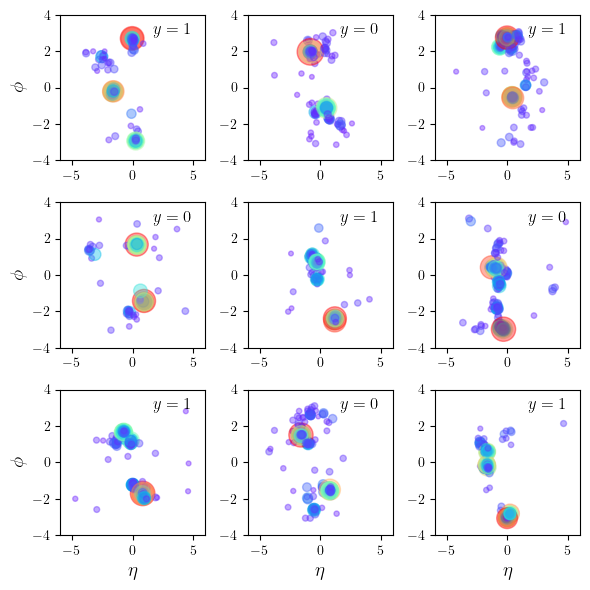

In [5]:
importlib.reload(tut)
tut.plot_events(events, targets)

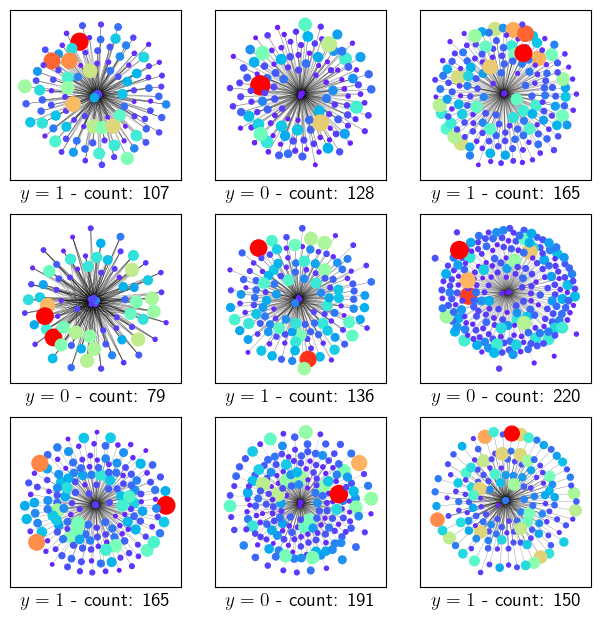

In [6]:
N = 9
x = [torch.tensor(events[i].reshape(1, -1, 3)) for i in range(N)]
y = torch.tensor(targets[:N].astype(int)).view(-1, 1)
tut.plot_graphs(zip(x, y), scale=8)

## Configuration

In [7]:
# name of model
# -----------------------------------------
name = 'sigbkg'

# create new configuration
config = mlp.Config(name, dirname='GNN_PyG')

# graph configuration
# -----------------------------------------
config('dR_max',          0.8) # radius of the attention domain in (eta, phi):
                               # particles i and j are connected only
                               # if dR_ij < dR_max. (Try 0.4, 0.8, 1.2.)
config('alpha',           1.0) # initial value of the Gaussian parameter alpha

# training configuration
# -----------------------------------------
config('train_size',   32_000) # training sample size
config('test_size',     3_900) # test sample size
config('val_size',        100) # validation sample size
config('batch_size',       16) # number of graphs / batch
config('monitor_step',     20) # monitor training every n iterations
config('frac',          0.015) # save model if average loss decreases by
                               # more than fraction "frac"

# optimizer / scheduler configuration
# (the same schedule as in tutorial_GNN.ipynb: 4 epochs, with the
#  learning rate halved at the end of each epoch)
# -----------------------------------------
n_epochs = 4
config('n_epochs', n_epochs)

iterations_per_epoch = config('train_size') // config('batch_size')
config('n_iterations', n_epochs * iterations_per_epoch)

config('n_steps', n_epochs)               # number of training steps
config('n_iters_per_step', iterations_per_epoch)
config('base_lr', 2.e-3)                  # initial learning rate
config('gamma',   0.5)                    # learning rate scale factor

configfile = config('file/config')
print(f'\nSave configuration to file {configfile}\n')
config.save()

print(config)


Save configuration to file runs/GNN_PyG/sigbkg_config.yaml

name: sigbkg
file:
  losses: runs/GNN_PyG/sigbkg_losses.csv
  params: runs/GNN_PyG/sigbkg_params.pth
  init_params: runs/GNN_PyG/sigbkg_init_params.pth
  plots: runs/GNN_PyG/sigbkg_plots.png
  config: runs/GNN_PyG/sigbkg_config.yaml
dR_max: 0.8
alpha: 1.0
train_size: 32000
test_size: 3900
val_size: 100
batch_size: 16
monitor_step: 20
frac: 0.015
n_epochs: 4
n_iterations: 8000
n_steps: 4
n_iters_per_step: 2000
base_lr: 0.002
gamma: 0.5



## Prepare datasets and dataloaders
  1. Scale data.
  2. Build a list of `numpy` arrays, one per event. Why a list rather than a single array?
  3. Split data into training, testing, and validation sets.

### Scale data

Scale the node features and convert them to 32-bit floats. We also keep a copy of the **unscaled** $(\eta, \phi)$ of every particle. PyG calls such coordinates the **positions** of the nodes (attribute `pos`). We use them to compute the distances $\Delta R$ between particles, which must be computed in physical units so that the wraparound in azimuth, $\phi = +\pi \leftrightarrow \phi = -\pi$, is handled correctly.

In [8]:
print('\n\tScale data')
#                  pT, eta,   phi
scale = np.array([[50,   5, np.pi]], dtype=np.float32)

# scaled node features: (pT/50, eta/5, phi/pi)
sevents = [event.astype(np.float32) / scale for event in events]

# unscaled node positions: (eta, phi)
positions = [event[:, 1:3].astype(np.float32) for event in events]

targets = targets.astype(np.float32)


	Scale data


## Datasets

Create a dataset of graphs, one for every event. Every particle in an event is modeled as a node (or vertex) of a graph.

### Edges: the attention domain
Particles $i$ and $j$ are connected by an edge only if they are within the **attention domain**
$$\Delta R_{ij} = \sqrt{(\eta_i - \eta_j)^2 + (\Delta \phi_{ij})^2} < \Delta R_\text{max},$$
where $\Delta\phi_{ij}$ is the azimuthal difference, taking the wraparound into account. Every particle is connected to itself ($\Delta R_{ii} = 0$). The class `tut.RadiusConnection` returns the `edge_index` tensor of shape $[2, K]$ that lists the $K$ connected (target, source) pairs.

Let's see how many of the $n^2$ possible edges survive for the first event, and look at the edge weights (defined below).

In [9]:
importlib.reload(tut)

print('\n\tTest RadiusConnection')

pos        = torch.tensor(positions[0])           # [n, 2]
n          = len(pos)

connection = tut.RadiusConnection(config('dR_max'))
edge_index = connection(pos)                      # [2, K]
weights    = tut.gaussian_edge_weights(pos, edge_index, alpha=config('alpha'))

K = edge_index.shape[1]
print(f'number of nodes:            {n:8d}')
print(f'number of possible edges:   {n*n:8d}')
print(f'number of edges kept:       {K:8d} ({100*K/n**2:.1f}%)')
print('shapes:', pos.shape, edge_index.shape, weights.shape)


	Test RadiusConnection
number of nodes:                 107
number of possible edges:      11449
number of edges kept:           3447 (30.1%)
shapes: torch.Size([107, 2]) torch.Size([2, 3447]) torch.Size([3447])


### How much memory do the edges need?

PyG stores the edge index as 64-bit integers, so every edge costs $2 \times 8 = 16$ bytes. A fully-connected graph with $n$ nodes therefore needs $16 n^2$ bytes. The cell below estimates the memory needed to store the edges of **all** the events, for a fully-connected graph and for our attention domain.

This is why the dataset below builds the edges of a graph **only when the graph is needed**, that is, when it is placed in a batch, rather than building and storing the edges of every graph in advance.

In [10]:
nsample = 1000                       # estimate from a subsample of events
n_full = 0
n_kept = 0
for i in range(nsample):
    pos = torch.tensor(positions[i])
    n_full += len(pos)**2
    n_kept += connection(pos).shape[1]

nevents = len(positions)
GB = 1024**3
print(f'fraction of edges kept (dR < {config("dR_max")}): {n_kept/n_full:8.3f}')
print(f'memory, fully-connected graphs: {16 * n_full * nevents/nsample / GB:8.2f} GB')
print(f'memory, attention domain:       {16 * n_kept * nevents/nsample / GB:8.2f} GB')

fraction of edges kept (dR < 0.8):    0.273
memory, fully-connected graphs:    13.10 GB
memory, attention domain:           3.57 GB


### Graph Dataset

A graph dataset is a collection of `PyG` `Data` objects. Each `Data` object holds the node features `x` (scaled), the node positions `pos` (unscaled $\eta, \phi$), the `edge_index`, and the target `y`. `tut.SparseGraphDataset` stores only `x`, `pos`, and `y`; the `edge_index` of a graph is built when the graph is requested.

In [11]:
importlib.reload(tut)

train_size = config('train_size')
val_size   = config('val_size')
test_size  = config('test_size')

connection = tut.RadiusConnection(config('dR_max'))

# training dataset (this defines the empirical risk to be minimized)
print('\n\tTraining data')
train_data = tut.SparseGraphDataset(
    sevents, positions, targets, start=0, end=train_size,
    connection=connection)

# a random subset of the training data to check for overtraining
# by comparing with the empirical risk from the validation set
print('training data for validation')
train_data_val = tut.SparseGraphDataset(
    sevents, positions, targets, start=0, end=train_size,
    random_sample_size=val_size, connection=connection)

# validation dataset (for monitoring training)
print('validation data')
val_data = tut.SparseGraphDataset(
    sevents, positions, targets, start=train_size, end=train_size + val_size,
    connection=connection)

# test dataset
print('test data')
test_data = tut.SparseGraphDataset(
    sevents, positions, targets,
    start=train_size + val_size, end=train_size + val_size + test_size,
    connection=connection)

print('\ntrain_data[0]:', train_data[0])


	Training data
SparseGraphDataset: 32000 graphs
training data for validation
SparseGraphDataset: 100 graphs
validation data
SparseGraphDataset: 100 graphs
test data
SparseGraphDataset: 3900 graphs

train_data[0]: Data(x=[107, 3], edge_index=[2, 3447], y=[1], pos=[107, 2])


## DataLoaders

In [12]:
print('train data loader')
train_loader = DataLoader(
    train_data, batch_size=config('batch_size'), shuffle=True)

print('train data loader for validation')
train_loader_val = DataLoader(
    train_data_val, batch_size=len(train_data_val))

print('validation data loader')
val_loader = DataLoader(
    val_data, batch_size=len(val_data))

print('test data loader')
test_loader = DataLoader(test_data, batch_size=100)

train data loader
train data loader for validation
validation data loader
test data loader


A batch of graphs is itself a (big) graph: PyG concatenates the nodes of all graphs in the batch and shifts the node indices in each `edge_index` so that they point to the right rows. The vector `batch.batch` records the graph to which each node belongs.

In [13]:
batch = next(iter(train_loader))
print('x          ', batch.x.shape)
print('pos        ', batch.pos.shape)
print('edge_index ', batch.edge_index.shape)
print('y          ', batch.y.shape)
print('batch      ', batch.batch.shape)

x           torch.Size([2040, 3])
pos         torch.Size([2040, 2])
edge_index  torch.Size([2, 76578])
y           torch.Size([16])
batch       torch.Size([2040])


## Build Model

### Conceptual framework
Consider a graph $G = (V, E)$ with $n$   nodes (i.e., vertices) $V = \{V_0,\cdots, V_{n-1}\}$ and $K$ edges $E = \{E_0, \cdots, E_{K-1} \}$. An **edge** can be modeled as the triplet $(i, j, e_{(i,j)})$, where $i$ and $j$ are indices that identify the two connecting nodes $V_i$ and $V_j$, respectively, and $e_{(i,j)}$ are the attributes associated with the edge identified by the **edge index** $(i, j)$. If a **message** $M$ is passed from vertex $V_j$ to $V_i$,
$$V_j \rightarrow M \rightarrow V_i,$$
the vertex $V_j$ is called a **source node**, while the receiving vertex $V_i$ is called a **target node**. A message is a function of the attributes of a source node and attributes of the associated edge; in the simplest case  a message is a vector of scaled source attributes where the scaling is the edge attribute or **weight**.

Given a target node, all messages from the source nodes to which the target is connected are entered into an **aggregation** function which  creates a new vector of attributes that replaces the existing attributes of the target node.

### Adjacency matrix $A$
An event with $n$ particles can be modeled as a graph with $n$ nodes. Inspired by IceCube, we model the attributes associated with the edges of the graph as an $n \times n$ adjacency matrix $A$ with matrix elements
\begin{align}
    e_{(i,j)} & = \frac{\exp(-\alpha \, \Delta R_{ij}^2)}{\sum_{k \in N(i)} \exp(-\alpha \, \Delta R_{ik}^2)} \quad \text{if } j \in N(i), \\
    e_{(i,j)} & = 0 \quad \text{otherwise},
\end{align}
where $N(i) = \{j : \Delta R_{ij} < \Delta R_\text{max}\}$ is the **attention domain** of particle $i$ and $\alpha > 0$ is a free parameter. Each row of $A$ is a **softmax** of $-\alpha \Delta R_{ij}^2$, that is, a Gaussian kernel normalized to unit sum. (To keep $\alpha$ positive, we fit $\log \alpha$.)

An adjacency matrix implicitly encodes the edge index $(i, j)$ between nodes $i$ and $j$ and explicitly encodes the edge attributes $e_{(i,j)}$. In `PyG`, the edge index is defined with a tensor of shape $[2, K]$ called `edge_index` such that the target and source nodes, `trg_nodes` and `src_nodes`, respectively, are given by
```python
    trg_nodes, src_nodes = edge_index
```
The use of edge indices, basically the "address" of a **non-zero** element of the adjacency matrix, makes it possible for `PyG` to handle **sparse** adjacency matrices efficiently: only the $K$ non-zero elements are stored and used, rather than all $n^2$ elements.

With $\Delta R_\text{max} = 0.8$, about a quarter of the $n^2$ pairs of particles are connected. (Why so many? Because the particles are concentrated in jets.) The fully-connected graph is recovered in the limit $\Delta R_\text{max} \rightarrow \infty$.

### Graph Convolution: $\texttt{GNNConv}$
We implement a graph convolutional layer that differs from the one implemented by IceCube.
As in most GNNs, the nodes are concatenated into a matrix, $V$, of shape $(n, d)$, where $n$ is the number of nodes and $d$ is the dimensionality of the input feature space. The graph convolution operation is defined by the following computations
\begin{align}
    A & = f(V),&\quad\text{node adjacency  }\\
    X & = \sigma(V W_1^T + B_1), &\quad\text{node embedding}\\
    X^\prime & = A X, &\quad\text{node attention  }\\
    Z & = X^\prime W_2^T + B_2,
\end{align}
that is, a linear function that maps the vertices of $V$ to a vector in an embedding space of dimension $h$, thereby yielding a matrix of shape $(n, h)$. Then a nonlinear operation, $\sigma(*)$, is applied (usually, elementwise) to every element of the embedded vectors. The adjacency matrix $A$, which we choose to be a function of the input nodes $V$, defines the *neighborhood* structure of the graph (see details above). The closer neighbors are weighted more than those further away. The learnable parameter $\alpha$ determines the scale of the nearest neighbor domains.    

Next we compute $X^\prime = AX$, which implements a simple **attention** mechanism in which each target node "pays attention" to its nearest neighbors. Finally, another linear operation is performed which embeds the vector in $X^\prime$ in another vector space.

In [14]:
class GNNConv(nn.Module):
    def __init__(self, in_features, embed_dim, out_features, 
                 activation=nn.ReLU()):

        super().__init__()

        self.activation = activation
        
        # we embed the "n" input vertices in a larger vector
        # space of dimension h = embed_dim
        self.embed_dim = embed_dim
        self.embed  = nn.Linear(in_features, embed_dim)
        self.linear = nn.Linear(embed_dim, out_features)

    def forward(self, V, edge_index, edge_attrs):
        # V[n=num_nodes, d=in_features]  - nodes in the current batch
        # edge_index[2, K=num_edges] - edges in the current batch
        # edge_attrs[K] - associated edge attributes

        trg_nodes, src_nodes = edge_index

        # 1: Embed input nodes in vector space of h = embed_dim dimensions
        X = self.activation(self.embed(V)) # X[num_nodes, embed_dim]

        # 2: Create messages associated with edges. Note: These edges
        #    may form self-consistent sub-graphs. (In the present context,
        #    a message from a source node to a target node is a scaled
        #    vector, weight * vector, in the embedding space but with
        #    the weight computed in the input space using the formula
        #    for e_(i,j) given above.)
        #
        #    Note: X has shape [num_nodes, embed_dim], while X[src_nodes]
        #    has shape [num_edges, embed_dim] and weights has shape
        #    [num_edges, ]. Therefore, we need to change the shape of
        #    weights to [num_edges, 1] so that every feature of a given
        #    source node is scaled by the weight associated with the
        #    associated edge.
        #
        #    Creating the messages and calling scatter is mathematically
        #    equivalent to computing X^prime = AX.

        messages = edge_attrs.unsqueeze(-1) * X[src_nodes]

        # 3. Send messages from all source nodes to the target nodes
        #    to which they are linked. Then aggregate these messages
        #    by summing them vectorially per target nodes. These
        #    operations, which are equivalent to computing A*X, can
        #    be done with the scatter function.
        #
        # calling sequence:
        #    scatter(messages, trg_nodes, dim=0, dim_size=num_nodes, reduce='sum')
        #
        #    dim=0 specifies that the messages to a given target node
        #    should be summed vertically, that is, along the dim=0 axis.
        #    dim_size=num_nodes guarantees one output row per node.

        X = scatter(messages, trg_nodes, dim=0, dim_size=V.size(0),
                    reduce='sum')

        # 4. Final transformation
        Z = self.linear(X)

        return Z

Test `GNNConv`

In [15]:
batch = next(iter(train_loader)).to(DEVICE)

edge_attrs = tut.gaussian_edge_weights(batch.pos, batch.edge_index,
                                       alpha=config('alpha'),
                                       num_nodes=batch.num_nodes)

print('edge_attrs', edge_attrs.shape, edge_attrs.dtype)
print('x         ', batch.x.shape, batch.x.dtype)
print('y         ', batch.y.shape, batch.y.dtype)

conv = GNNConv(3, 5, 2).to(DEVICE)
X = conv(batch.x, batch.edge_index, edge_attrs)
print('X         ', X.shape)

edge_attrs torch.Size([102850]) torch.float32
x          torch.Size([2254, 3]) torch.float32
y          torch.Size([16]) torch.float32
X          torch.Size([2254, 2])


### Build GNN

In [16]:
class GNN(mlp.Model):

    def __init__(self, in_features, embed_dim, out_features,
                 activation=nn.SiLU(),
                 dropout=0.5,
                 alpha=1.0):

        # initialize base class
        super().__init__()

        self.activation = activation

        # Note use of nn.Parameter to tell PyTorch that log(alpha)
        # is to be fitted. Fitting log(alpha) rather than alpha
        # guarantees that alpha = exp(log(alpha)) stays positive.
        self.log_alpha = nn.Parameter(torch.log(torch.tensor([float(alpha)])))

        self.conv1  = GNNConv(in_features, embed_dim, embed_dim)
        self.conv2  = GNNConv(embed_dim, embed_dim, embed_dim)
        self.dropout= nn.Dropout(dropout)
        self.output = nn.Sequential(nn.Linear(embed_dim, out_features),
                                    nn.Sigmoid())

    def alpha(self):
        return torch.exp(self.log_alpha)

    def forward(self, batch):
        V = batch.x
        # V[num_nodes, in_features]  : all nodes in the batch

        edge_index = batch.edge_index
        # edge_index[2, num_edges]   : edges within the attention domain

        # Compute edge weights from the unscaled positions (eta, phi).
        # This is equivalent to computing the non-zero elements of A.
        edge_attrs = tut.gaussian_edge_weights(batch.pos, edge_index,
                                               self.alpha(),
                                               num_nodes=V.size(0))

        X = self.conv1(V, edge_index, edge_attrs)
        X = self.activation(X)
        X = self.dropout(X)

        X = self.conv2(X, edge_index, edge_attrs)
        X = self.activation(X)
        X = self.dropout(X)

        # average features over the nodes of each graph
        X = global_mean_pool(X, batch.batch)

        y_pred = self.output(X)

        return y_pred

## Instantiate training objects
  1. `model`
  2. `optimizer`
  1. `objective`
  2. `scheduler`
  3. `monitor`

In [17]:
importlib.reload(mlp)

model = GNN(in_features=3, embed_dim=40, out_features=1,
            alpha=config('alpha')).to(DEVICE)
print(model)
print('number of parameters:', mlp.number_of_parameters(model))
print()

optimizer = torch.optim.Adam(model.parameters(), lr=config('base_lr'))

# make a specialized objective from mlp.Objective
class GNNObjective(mlp.Objective):
    def __init__(self, model, avgloss):
        super().__init__(model, avgloss)

    def forward(self, batch):
        batch = batch.to(DEVICE)
        y_pred = self.model(batch).reshape(batch.y.shape)
        return self.avgloss(y_pred, batch.y)

objective = GNNObjective(model, nn.BCELoss()).to(DEVICE)

# Instantiate learning rate step scheduler
scheduler = mlp.LRStepScheduler(
    optimizer,  
    n_steps=config('n_steps'), 
    n_iters_per_step=config('n_iters_per_step'), 
    base_lr=config('base_lr'), 
    gamma=config('gamma')
)

# Instantiate object that saves average losses to
# a csv file for realtime monitoring, as well as
# the model with the lowest average loss
monitor = mon.Monitor(
    config('n_iterations'),
    config('file/losses'),
    monitorstep=config('monitor_step'),
    newlossfile=True,
    frac=config('frac'),
    model=model,
    paramsfile=config('file/params')
)

GNN(
  (activation): SiLU()
  (conv1): GNNConv(
    (activation): ReLU()
    (embed): Linear(in_features=3, out_features=40, bias=True)
    (linear): Linear(in_features=40, out_features=40, bias=True)
  )
  (conv2): GNNConv(
    (activation): ReLU()
    (embed): Linear(in_features=40, out_features=40, bias=True)
    (linear): Linear(in_features=40, out_features=40, bias=True)
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (output): Sequential(
    (0): Linear(in_features=40, out_features=1, bias=True)
    (1): Sigmoid()
  )
)
number of parameters: 5122

number of milestones:          3

Step | Milestone | LR
-----------------------------
   0 |         0 | 2.0e-03   
-----------------------------
   1 |      2000 | 1.0e-03   
   2 |      4000 | 5.0e-04   
   3 |      6000 | 2.5e-04   



## Define trainer

In [18]:
importlib.reload(mlp)

def train(objective, optimizer, scheduler, monitor,
          train_loader, train_small_loader, val_loader, nepochs):

    for epoch in range(nepochs):

        for batch in train_loader:

            # set mode to training so that training-specific
            # operations such as dropout, etc., are enabled.
            objective.train()

            R = objective(batch)

            optimizer.zero_grad()     # zero gradients

            R.backward()              # compute gradients

            # limit the size of the gradient to avoid large jumps
            torch.nn.utils.clip_grad_norm_(objective.model.parameters(), 1)

            optimizer.step()          # make a single step in average loss

            # check whether to update learning rate
            scheduler.step()

            if monitor.step():

                # set mode to evaluation so that training-specific
                # operations such as dropout, etc., are disabled.
                objective.eval()

                # no gradients are needed to compute the losses
                with torch.no_grad():
                    t_batch = next(iter(train_small_loader))
                    t_loss  = objective(t_batch).item()

                    v_batch = next(iter(val_loader))
                    v_loss  = objective(v_batch).item()

                # return current learning rate
                lr = scheduler.lr()

                # update loss file
                monitor(t_loss, v_loss, lr, epoch)
    print()

## Train Model

In [19]:
TRAIN = True

if TRAIN:

    monitor.start()
    
    train(objective, optimizer, scheduler, monitor,
          train_loader, train_loader_val, val_loader, n_epochs)

    monitor.terminate(5)

monlosses runs/GNN_PyG/sigbkg_losses.csv

		learning rate:  2.000e-03
      1980| 24.76%|00:01:28|00:04:29|  22.4 it/s|3.931e-01|3.475e-01|         0|
		learning rate:  1.000e-03
      3980| 49.76%|00:02:55|00:02:57|  22.7 it/s|3.959e-01|3.218e-01|         1|
		learning rate:  5.000e-04
      5980| 74.76%|00:04:24|00:01:29|  22.6 it/s|3.435e-01|3.055e-01|         2|
		learning rate:  2.500e-04
      7980| 99.76%|00:05:53|00:00:00|  22.6 it/s|3.191e-01|3.132e-01|         3|

	Terminating standalone loss monitor...
	Done!


## Plot Results

  1. Confusion matrix for signals defined by $y \geq 1/2$.
  2. Classifier distribution $\hat{y} = D(G)$.
  3. ROC curve

In [20]:
importlib.reload(tut)

params_filename = config('file/params')

# load the best model and set it to evaluation mode (no dropout)
model.load(params_filename)
model.eval()

print(f'fitted alpha: {model.alpha().item():.2f}')

y_hat = []
label = []
with torch.no_grad():
    for batch in tqdm(test_loader):
        batch = batch.to(DEVICE)
        label.append( batch.y.cpu().numpy().flatten() )
        y_hat.append( model(batch).cpu().numpy().flatten() )

# concatenate the per-batch arrays into single arrays
y_hat = np.concatenate(y_hat)
test_targets = np.concatenate(label)

y_hat.shape, test_targets.shape

fitted alpha: 0.02


100%|███████████████████████████████████████████████████████████| 39/39 [00:03<00:00,  9.86it/s]


((3900,), (3900,))

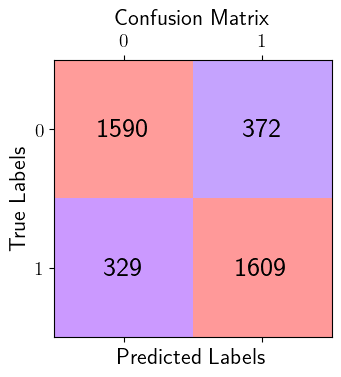

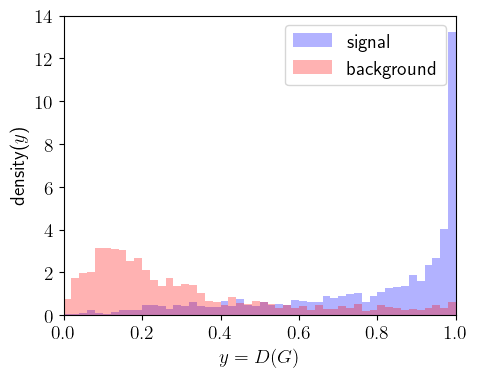

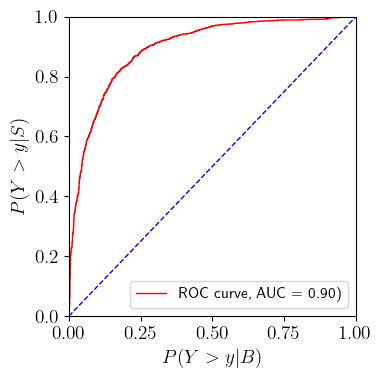

In [21]:
test_preds = (y_hat > 0.5).astype(int)

tut.plot_confusion_matrix(test_targets, test_preds)
tut.histogram_classifier_outputs(test_targets, y_hat)
tut.plot_roc(test_targets, y_hat)